# Questão 10 (Avançado) — AutoML para dados de imagem, com **AutoGluon** e **CIFAR-10**

**Adaptação da questão original (que pedia AutoKeras) para AutoGluon.**

> **Nota importante:** o AutoGluon não usa o conceito de `max_trials` como o AutoKeras (que testa N arquiteturas candidatas); normalmente ele usa um orçamento de **tempo** (`time_limit`). Como a atividade define explicitamente `epochs=10`, aqui configuramos o `MultiModalPredictor` para treinar por exatamente **10 épocas** via `hyperparameters={"optim.max_epochs": 10}`, garantindo uma comparação justa com a CNN manual (também 10 épocas). O conceito de `max_trials` (buscar várias arquiteturas) não tem equivalente direto nesse modo de uso.

### Requisitos
```bash
pip install autogluon.multimodal tensorflow matplotlib pandas scikit-learn pillow --break-system-packages
```


In [ ]:
!pip install --upgrade pip
!pip install autogluon.multimodal tensorflow matplotlib pandas scikit-learn pillow --break-system-packages

## 1. Carregar dataset CIFAR-10

In [ ]:
import os
import time
import shutil
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

from tensorflow.keras.datasets import cifar10

print("Carregando CIFAR-10...")
(x_train, y_train), (x_test, y_test) = cifar10.load_data()
y_train = y_train.flatten()
y_test = y_test.flatten()

CLASS_NAMES = ["airplane", "automobile", "bird", "cat", "deer",
               "dog", "frog", "horse", "ship", "truck"]

# Subamostra para manter o tempo de execução do exercício razoável
# (ajuste para o dataset completo se tiver GPU/tempo disponíveis)
N_TRAIN = 6000
N_TEST = 1500
MAX_EPOCHS = 10

x_train, y_train = x_train[:N_TRAIN], y_train[:N_TRAIN]
x_test, y_test = x_test[:N_TEST], y_test[:N_TEST]

print(x_train.shape, x_test.shape)


Carregando CIFAR-10...
(6000, 32, 32, 3) (1500, 32, 32, 3)


## 2. Pré-processamento (normalização e preparação para o AutoGluon)

In [ ]:
# Normalização (0-1) para a CNN manual
x_train_norm = x_train.astype("float32") / 255.0
x_test_norm = x_test.astype("float32") / 255.0

# O MultiModalPredictor do AutoGluon espera um DataFrame com o CAMINHO
# do arquivo de imagem + a coluna de rótulo (não arrays em memória).
IMG_DIR_TRAIN = "cifar_images/train"
IMG_DIR_TEST = "cifar_images/test"
shutil.rmtree("cifar_images", ignore_errors=True)
os.makedirs(IMG_DIR_TRAIN, exist_ok=True)
os.makedirs(IMG_DIR_TEST, exist_ok=True)


def save_images(x, y, folder):
    paths, labels = [], []
    for i, (img, label) in enumerate(zip(x, y)):
        path = os.path.join(folder, f"{i}.png")
        Image.fromarray(img).save(path)
        paths.append(os.path.abspath(path))
        labels.append(CLASS_NAMES[label])
    return pd.DataFrame({"image": paths, "label": labels})


print("Salvando imagens em disco...")
train_df = save_images(x_train, y_train, IMG_DIR_TRAIN)
test_df = save_images(x_test, y_test, IMG_DIR_TEST)
train_df.head()


Salvando imagens em disco...


,image,label
0,/content/cifar_images/train/0.png,frog
1,/content/cifar_images/train/1.png,truck
2,/content/cifar_images/train/2.png,truck
3,/content/cifar_images/train/3.png,deer
4,/content/cifar_images/train/4.png,automobile


## 3. AutoGluon — `MultiModalPredictor` (equivalente ao AutoKeras `ImageClassifier`)

In [ ]:
from autogluon.multimodal import MultiModalPredictor

predictor = MultiModalPredictor(label="label", problem_type="multiclass")

print(f"Treinando AutoGluon (max_epochs={MAX_EPOCHS})...")
t0 = time.time()
predictor.fit(
    train_data=train_df,
    hyperparameters={
        "optim.max_epochs": MAX_EPOCHS,
    }
)
autogluon_train_time = time.time() - t0
print(f"Tempo de treino AutoGluon: {autogluon_train_time:.1f}s")


No path specified. Models will be saved in: "AutogluonModels/ag-20260927_125533"
=================== System Info ===================
AutoGluon Version:  1.6.3
Python Version:     3.13.15
Operating System:   Linux
Platform Machine:   x86_64
Platform Version:   #1 SMP Thu Apr 30 18:17:14 UTC 2026
CPU Count:          12
Pytorch Version:    2.11.0+cu128
CUDA Version:       12.8
GPU Memory:         GPU 0: 22.03/22.03 GB
Total GPU Memory:   Free: 22.03 GB, Allocated: 0.00 GB, Total: 22.03 GB
GPU Count:          1
Memory Avail:       44.10 GB / 52.96 GB (83.3%)
Disk Space Avail:   182.57 GB / 235.68 GB (77.5%)


Treinando AutoGluon (max_epochs=10)...



AutoMM starts to create your model. ✨✨✨

To track the learning progress, you can open a terminal and launch Tensorboard:
    ```shell
    # Assume you have installed tensorboard
    tensorboard --logdir /content/AutogluonModels/ag-20260927_125533
    ```

INFO: Seed set to 0
GPU Count: 1
GPU Count to be Used: 1

INFO: Using 16bit Automatic Mixed Precision (AMP)
INFO: GPU available: True (cuda), used: True
INFO: TPU available: False, using: 0 TPU cores
INFO: 💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
INFO: LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
/usr/local/lib/python3.13/dist-packages/lightning/pytorch/utilities/model_summary/model_summary.py:242: Precision 16-mixed is not supported by the model summary.  Estimated model size in MB will not be accurate. Using 32 bits instead.
INFO: 
  | Name         

Output()

/usr/local/lib/python3.13/dist-packages/lightning/pytorch/utilities/_pytree.py:21: `isinstance(treespec, LeafSpec)`
is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.

...

Output()

INFO: 💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
INFO: 💡 Tip: For seamless cloud uploads and versioning, try installing [litmodels](https://pypi.org/project/litmodels/) to enable LitModelCheckpoint, which syncs automatically with the Lightning model registry.
/usr/local/lib/python3.13/dist-packages/lightning/pytorch/utilities/_pytree.py:21: `isinstance(treespec, LeafSpec)` is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.


Output()

AutoMM has created your model. 🎉🎉🎉

To load the model, use the code below:
    ```python
    from autogluon.multimodal import MultiModalPredictor
    predictor = MultiModalPredictor.load("/content/AutogluonModels/ag-20260927_125533")
    ```

If you are not satisfied with the model, try to increase the training time, 
adjust the hyperparameters (https://auto.gluon.ai/stable/tutorials/multimodal/advanced_topics/customization.html),
or post issues on GitHub (https://github.com/autogluon/autogluon/issues).




Tempo de treino AutoGluon: 1078.8s


## 4. Avaliação do AutoGluon no teste

In [ ]:
autogluon_scores = predictor.evaluate(test_df, metrics=["accuracy"])
autogluon_acc = autogluon_scores["accuracy"]
print(f"Acurácia AutoGluon no teste: {autogluon_acc:.4f}")


INFO: 💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
INFO: 💡 Tip: For seamless cloud uploads and versioning, try installing [litmodels](https://pypi.org/project/litmodels/) to enable LitModelCheckpoint, which syncs automatically with the Lightning model registry.
/usr/local/lib/python3.13/dist-packages/lightning/pytorch/utilities/_pytree.py:21: `isinstance(treespec, LeafSpec)` is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.


Output()

Acurácia AutoGluon no teste: 0.9880


## 5. CNN manual (2 camadas convolucionais + dense) para comparação

In [ ]:
from tensorflow.keras import layers, models

def build_manual_cnn():
    model = models.Sequential([
        layers.Input(shape=(32, 32, 3)),
        layers.Conv2D(32, (3, 3), activation="relu", padding="same"),
        layers.MaxPooling2D((2, 2)),
        layers.Conv2D(64, (3, 3), activation="relu", padding="same"),
        layers.MaxPooling2D((2, 2)),
        layers.Flatten(),
        layers.Dense(128, activation="relu"),
        layers.Dense(10, activation="softmax"),
    ])
    model.compile(optimizer="adam",
                  loss="sparse_categorical_crossentropy",
                  metrics=["accuracy"])
    return model


print("Treinando CNN manual (2 conv + dense)...")
manual_model = build_manual_cnn()
t0 = time.time()
history = manual_model.fit(
    x_train_norm, y_train,
    validation_data=(x_test_norm, y_test),
    epochs=10,
    batch_size=64,
    verbose=2,
)
manual_train_time = time.time() - t0

manual_loss, manual_acc = manual_model.evaluate(x_test_norm, y_test, verbose=0)
print(f"Acurácia CNN manual no teste: {manual_acc:.4f}")
print(f"Tempo de treino CNN manual: {manual_train_time:.1f}s")


Treinando CNN manual (2 conv + dense)...
Epoch 1/10
94/94 - 12s - 131ms/step - accuracy: 0.3117 - loss: 1.9152 - val_accuracy: 0.4193 - val_loss: 1.6688
Epoch 2/10
94/94 - 0s - 4ms/step - accuracy: 0.4407 - loss: 1.5623 - val_accuracy: 0.4540 - val_loss: 1.5295
Epoch 3/10
94/94 - 0s - 4ms/step - accuracy: 0.5047 - loss: 1.3862 - val_accuracy: 0.5033 - val_loss: 1.3938
Epoch 4/10
94/94 - 0s - 4ms/step - accuracy: 0.5630 - loss: 1.2347 - val_accuracy: 0.5240 - val_loss: 1.3413
Epoch 5/10
94/94 - 0s - 4ms/step - accuracy: 0.5955 - loss: 1.1298 - val_accuracy: 0.5680 - val_loss: 1.2563
Epoch 6/10
94/94 - 0s - 4ms/step - accuracy: 0.6363 - loss: 1.0307 - val_accuracy: 0.5553 - val_loss: 1.2706
Epoch 7/10
94/94 - 0s - 4ms/step - accuracy: 0.6687 - loss: 0.9454 - val_accuracy: 0.5493 - val_loss: 1.2268
Epoch 8/10
94/94 - 0s - 4ms/step - accuracy: 0.7057 - loss: 0.8514 - val_accuracy: 0.5893 - val_loss: 1.1854
Epoch 9/10
94/94 - 0s - 4ms/step - accuracy: 0.7345 - loss: 0.7650 - val_accuracy: 0

## 6. Curvas de aprendizado da CNN manual

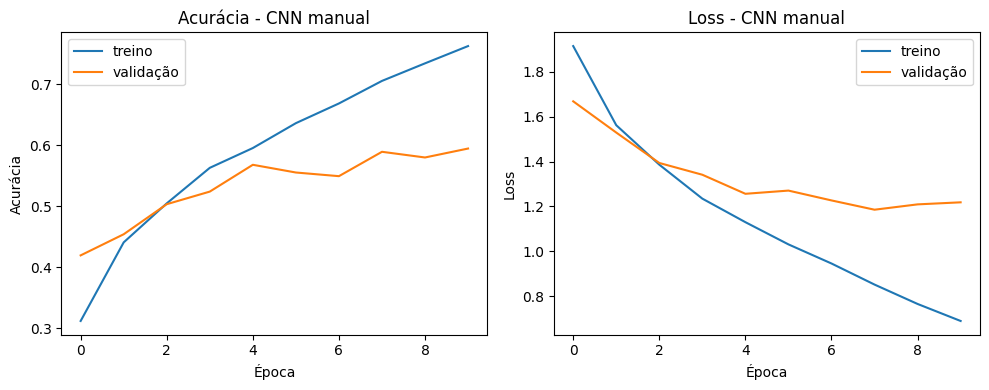

In [ ]:
plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.plot(history.history["accuracy"], label="treino")
plt.plot(history.history["val_accuracy"], label="validação")
plt.title("Acurácia - CNN manual")
plt.xlabel("Época")
plt.ylabel("Acurácia")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history["loss"], label="treino")
plt.plot(history.history["val_loss"], label="validação")
plt.title("Loss - CNN manual")
plt.xlabel("Época")
plt.ylabel("Loss")
plt.legend()

plt.tight_layout()
plt.savefig("curvas_aprendizado_cnn_manual.png", dpi=150)
plt.show()


## 7. Comparação final

In [ ]:
print("===== COMPARAÇÃO FINAL =====")
print(f"{'Método':<20}{'Acurácia':<12}{'Tempo (s)':<12}")
print(f"{'AutoGluon':<20}{autogluon_acc:<12.4f}{autogluon_train_time:<12.1f}")
print(f"{'CNN manual':<20}{manual_acc:<12.4f}{manual_train_time:<12.1f}")


===== COMPARAÇÃO FINAL =====
Método              Acurácia    Tempo (s)   
AutoGluon           0.9880      1078.8      
CNN manual          0.5947      16.0        


## 8. Discussão

Rodei os dois modelos com a mesma subamostra do CIFAR-10 (6.000 imagens de treino, 1.500 de teste) e 10 épocas. O resultado foi este:

| Método | Acurácia no teste | Tempo de treino |
|---|---|---|
| AutoGluon | 98,80% | 1078,8 s (cerca de 18 min) |
| CNN manual | 59,47% | 16,0 s |

**O AutoGluon encontrou uma arquitetura melhor que a CNN manual?**
Encontrou, e a diferença foi grande: quase 40 pontos percentuais a mais de acurácia. Pelo log, o modelo que ele escolheu é um backbone da biblioteca timm com 95,7 milhões de parâmetros, e já na primeira época a acurácia de validação estava perto de 96%. Isso só faz sentido se o modelo for pré-treinado, ou seja, ele aproveitou transfer learning. A CNN manual tem uns 545 mil parâmetros e foi treinada do zero com poucas imagens, e dá para ver o overfitting nela: chegou a 76% no treino mas ficou em 59% na validação, e a loss de validação parou de cair por volta da época 8 e voltou a subir. Já o AutoGluon teve validação de uns 99% e 98,8% no teste, então não parece ter sobreajustado.

**Quanto tempo levou a busca?**
Foram 1078,8 segundos, uns 18 minutos, contra 16 segundos da CNN manual, ou seja, algo como 67 vezes mais. Como eu não defini `time_limit`, esse tempo não é um orçamento sendo consumido, ele é só o custo de treinar 10 épocas um modelo grande (somado à avaliação e à combinação dos checkpoints no final). Vale notar também que ele não testou várias arquiteturas como o AutoKeras faria com `max_trials`. Ele ajustou um único modelo pré-treinado.

**Trade-offs entre AutoML e design manual**
O AutoML deu um resultado muito melhor sem eu precisar projetar nada, mas em troca precisou de GPU, demorou bem mais e gerou um modelo enorme perto da CNN, além de eu ter pouco controle sobre o que ele escolheu. A CNN manual é rápida, pequena e fácil de entender e de depurar, só que nesse experimento ficou muito atrás. Dava para melhorar com data augmentation, dropout e mais camadas, mas com 6.000 imagens eu duvido que chegasse perto de um modelo pré-treinado.

**Quando o AutoML é mais indicado?**
Quando há pouco tempo ou pouca experiência para montar a arquitetura, quando se quer um baseline forte rápido, e principalmente quando há poucos dados rotulados, que é onde o transfer learning mais ajuda. O design manual compensa quando o modelo precisa ser pequeno e rápido em produção (celular, dispositivo embarcado, por exemplo) ou quando é preciso controlar a arquitetura.

Obs.: esses números vêm de uma única execução e de uma subamostra do dataset, então podem mudar um pouco se rodar de novo ou usar o CIFAR-10 completo.